# Neural Network - Iris Dataset for week 15-16

**Topics covered:** perceptron, activation functions, forward/backward propagation, loss functions, SGD vs Adam, NumPy neural network from scratch, and model saving/loading with `pickle` and `joblib`.

**How to use:** Run cells from top to bottom. This notebook uses the Iris dataset built into Scikit-learn, so no manual dataset download is required.

The model predicts one of three Iris species from four measurements: sepal length, sepal width, petal length, and petal width.

Saving IRIS.csv to IRIS.csv

Dataset preview:
   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Dataset shape: (150, 5)

Target column: species
Input features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Samples after removing missing rows: 150


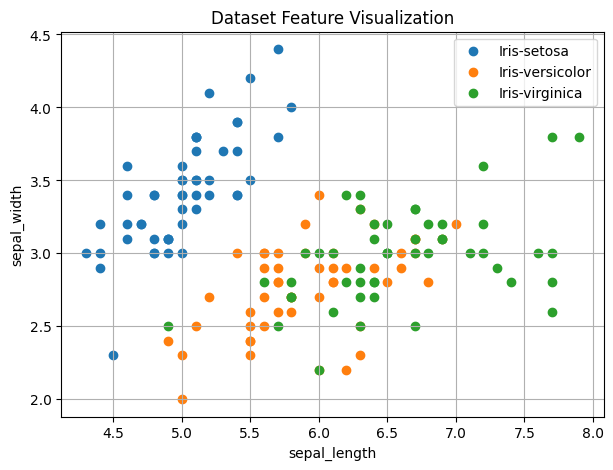


Training samples: 120
Testing samples: 30

--- PERCEPTRON EXAMPLE ---
Weighted sum: 0.40000000000000013
Step activation output: 1

ReLU example: [0 0 0 1 2]
Sigmoid example: [0.11920292 0.5        0.88079708]
Softmax example: [[0.65900114 0.24243297 0.09856589]]

Network architecture:
4 inputs -> 10 hidden neurons -> 3 outputs

First sample output probabilities: [0.11558517 0.30894796 0.57546687]
Probability sum: 1.0
Initial loss: 1.439

Backpropagation gradient shapes:
(4, 10)
(1, 10)
(10, 3)
(1, 3)

Final SGD loss: 0.174
Final Adam loss: 0.0208


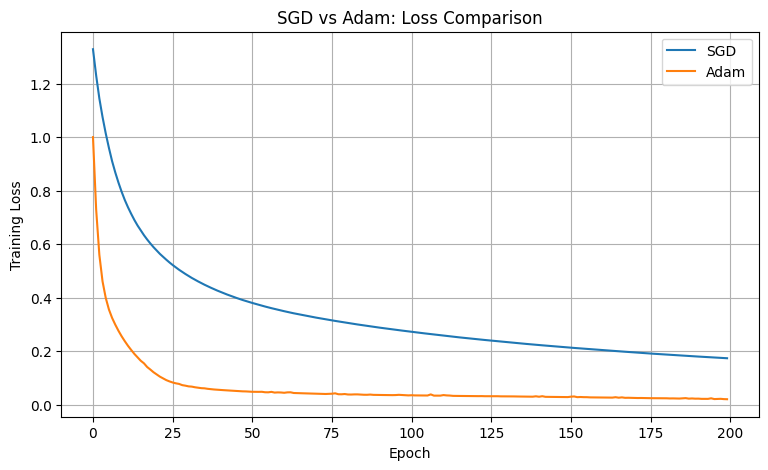


SGD Test Accuracy: 90.0 %
Adam Test Accuracy: 96.67 %


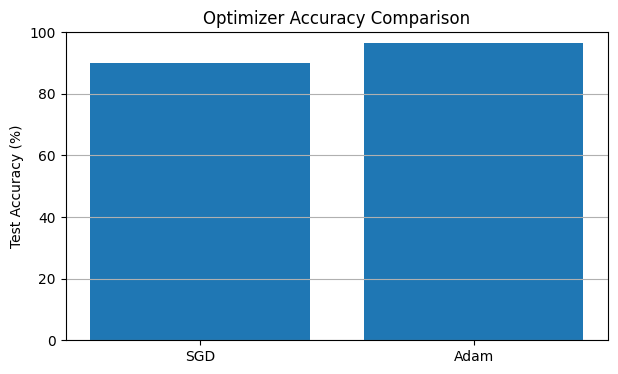


Classification Report — Adam
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



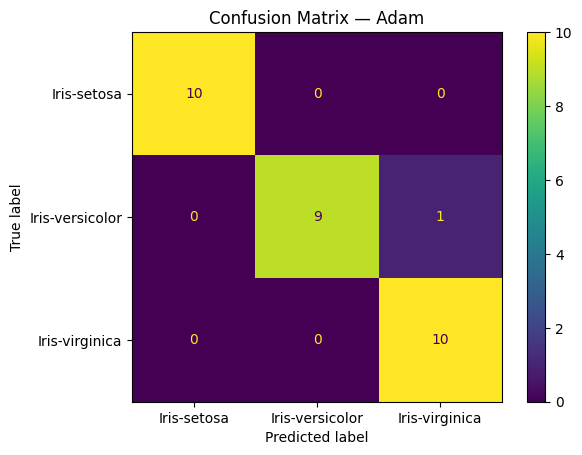


Model saved using pickle.

Example input: [4.4 3.  1.3 0.2]
Actual class: Iris-setosa
Pickle model prediction: Iris-setosa
Probabilities: [1. 0. 0.]

Joblib model prediction: Iris-setosa
Pickle and joblib predictions match: True



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL STEPS COMPLETED SUCCESSFULLY!


In [1]:
# ============================================================
# NEURAL NETWORK FROM SCRATCH - IRIS DATASET
# Perceptron, Activations, Forward/Backward Propagation,
# Loss, SGD vs Adam, Evaluation, Pickle and Joblib
# ============================================================

# STEP 1: UPLOAD YOUR DATASET
from google.colab import files
uploaded = files.upload()

# STEP 2: IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# STEP 3: LOAD AND IDENTIFY DATASET COLUMNS
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# Clean column names
df.columns = df.columns.astype(str).str.strip()

print("\nDataset preview:")
print(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nDataset shape:", df.shape)

# Automatically identify the target column
target_names = [
    "species", "variety", "class", "target", "label",
    "flower", "speciesname", "plant"
]

def clean_name(name):
    return "".join(ch for ch in name.lower() if ch.isalnum())

target_col = None

for col in df.columns:
    if clean_name(col) in target_names:
        target_col = col
        break

# If no familiar target name exists, use the last text column
if target_col is None:
    text_columns = df.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    if text_columns:
        target_col = text_columns[-1]

if target_col is None:
    raise ValueError(
        "Could not automatically identify the target column. "
        "Check your CSV column names."
    )

# Identify numerical input features
feature_cols = df.select_dtypes(include=np.number).columns.tolist()

# Remove ID/index columns, if present
feature_cols = [
    col for col in feature_cols
    if clean_name(col) not in ["id", "index", "unnamed0"]
]

if target_col in feature_cols:
    feature_cols.remove(target_col)

if len(feature_cols) == 0:
    raise ValueError("No numerical feature columns were found.")

# Keep required columns and remove missing rows
data = df[feature_cols + [target_col]].copy()
data = data.dropna()

X = data[feature_cols].to_numpy(dtype=float)

# Convert species names to numeric class labels
encoder = LabelEncoder()
y = encoder.fit_transform(data[target_col].astype(str))
class_names = encoder.classes_.tolist()
num_classes = len(class_names)

if num_classes < 2:
    raise ValueError("The target column must contain at least two classes.")

print("\nTarget column:", target_col)
print("Input features:", feature_cols)
print("Classes:", class_names)
print("Samples after removing missing rows:", len(y))

# STEP 4: VISUALIZE DATA
if len(feature_cols) >= 2:
    plt.figure(figsize=(7, 5))
    for class_id, name in enumerate(class_names):
        plt.scatter(
            X[y == class_id, 0],
            X[y == class_id, 1],
            label=name
        )
    plt.xlabel(feature_cols[0])
    plt.ylabel(feature_cols[1])
    plt.title("Dataset Feature Visualization")
    plt.legend()
    plt.grid(True)
    plt.show()

# STEP 5: TRAIN-TEST SPLIT
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize using training data only
mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std[std == 0] = 1

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

def one_hot(labels, classes):
    return np.eye(classes)[labels]

Y_train = one_hot(y_train, num_classes)
Y_test = one_hot(y_test, num_classes)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# STEP 6: PERCEPTRON EXAMPLE
print("\n--- PERCEPTRON EXAMPLE ---")

inputs = np.array([2, 3])
weights = np.array([0.4, 0.2])
bias = -1.0

z = np.dot(inputs, weights) + bias
output = int(z >= 0)

print("Weighted sum:", z)
print("Step activation output:", output)

# STEP 7: ACTIVATION FUNCTIONS AND LOSS
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def categorical_cross_entropy(Y, predictions):
    predictions = np.clip(predictions, 1e-9, 1.0)
    return -np.mean(np.sum(Y * np.log(predictions), axis=1))

print("\nReLU example:", relu(np.array([-2, -1, 0, 1, 2])))
print("Sigmoid example:", sigmoid(np.array([-2, 0, 2])))
print("Softmax example:", softmax(np.array([[2.0, 1.0, 0.1]])))

# STEP 8: INITIALIZE NEURAL NETWORK
# Input layer -> 10 hidden neurons -> output classes
def initialize_parameters(input_size, hidden_size, output_size, seed=42):
    rng = np.random.default_rng(seed)

    W1 = rng.standard_normal(
        (input_size, hidden_size)
    ) * np.sqrt(2 / input_size)

    b1 = np.zeros((1, hidden_size))

    W2 = rng.standard_normal(
        (hidden_size, output_size)
    ) * np.sqrt(1 / hidden_size)

    b2 = np.zeros((1, output_size))

    return [W1, b1, W2, b2]

input_size = X_train.shape[1]
hidden_size = 10
output_size = num_classes

parameters = initialize_parameters(
    input_size, hidden_size, output_size
)

print("\nNetwork architecture:")
print(input_size, "inputs ->", hidden_size,
      "hidden neurons ->", output_size, "outputs")

# STEP 9: FORWARD PROPAGATION
def forward(X, parameters):
    W1, b1, W2, b2 = parameters

    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = softmax(Z2)

    return Z1, A1, Z2, A2

Z1, A1, Z2, A2 = forward(X_train, parameters)

print("\nFirst sample output probabilities:", A2[0])
print("Probability sum:", A2[0].sum())
print("Initial loss:", round(
    categorical_cross_entropy(Y_train, A2), 4
))

# STEP 10: BACKPROPAGATION
def backward(X, Y, Z1, A1, A2, parameters):
    W1, b1, W2, b2 = parameters
    m = X.shape[0]

    # Output layer gradients
    dZ2 = (A2 - Y) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer gradients
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return [dW1, db1, dW2, db2]

gradients = backward(
    X_train, Y_train, Z1, A1, A2, parameters
)

print("\nBackpropagation gradient shapes:")
for g in gradients:
    print(g.shape)

# STEP 11: TRAIN USING SGD OR ADAM
def train_network(X, Y, optimizer="SGD",
                  epochs=200, batch_size=16,
                  learning_rate=0.01):

    params = initialize_parameters(
        X.shape[1], 10, Y.shape[1], seed=42
    )

    # Adam moving averages
    m = [np.zeros_like(p) for p in params]
    v = [np.zeros_like(p) for p in params]

    beta1 = 0.9
    beta2 = 0.999
    epsilon = 1e-8
    step = 0

    losses = []
    rng = np.random.default_rng(100)

    for epoch in range(epochs):
        indices = rng.permutation(len(X))
        X_shuffled = X[indices]
        Y_shuffled = Y[indices]

        for start in range(0, len(X), batch_size):
            xb = X_shuffled[start:start + batch_size]
            yb = Y_shuffled[start:start + batch_size]

            Z1, A1, Z2, A2 = forward(xb, params)
            grads = backward(xb, yb, Z1, A1, A2, params)

            if optimizer == "SGD":
                for i in range(len(params)):
                    params[i] -= learning_rate * grads[i]

            elif optimizer == "Adam":
                step += 1

                for i in range(len(params)):
                    m[i] = beta1 * m[i] + (1 - beta1) * grads[i]
                    v[i] = beta2 * v[i] + (1 - beta2) * grads[i]**2

                    m_hat = m[i] / (1 - beta1**step)
                    v_hat = v[i] / (1 - beta2**step)

                    params[i] -= (
                        learning_rate * m_hat /
                        (np.sqrt(v_hat) + epsilon)
                    )

        _, _, _, predictions = forward(X, params)
        losses.append(categorical_cross_entropy(Y, predictions))

    return params, losses

sgd_parameters, sgd_losses = train_network(
    X_train, Y_train,
    optimizer="SGD",
    epochs=200,
    learning_rate=0.01
)

adam_parameters, adam_losses = train_network(
    X_train, Y_train,
    optimizer="Adam",
    epochs=200,
    learning_rate=0.01
)

print("\nFinal SGD loss:", round(sgd_losses[-1], 4))
print("Final Adam loss:", round(adam_losses[-1], 4))

# STEP 12: COMPARE LOSS GRAPHS
plt.figure(figsize=(9, 5))
plt.plot(sgd_losses, label="SGD")
plt.plot(adam_losses, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD vs Adam: Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

# STEP 13: EVALUATE MODELS
def predict(X, parameters):
    _, _, _, probabilities = forward(X, parameters)
    return np.argmax(probabilities, axis=1)

sgd_predictions = predict(X_test, sgd_parameters)
adam_predictions = predict(X_test, adam_parameters)

sgd_accuracy = accuracy_score(y_test, sgd_predictions)
adam_accuracy = accuracy_score(y_test, adam_predictions)

print("\nSGD Test Accuracy:", round(sgd_accuracy * 100, 2), "%")
print("Adam Test Accuracy:", round(adam_accuracy * 100, 2), "%")

plt.figure(figsize=(7, 4))
plt.bar(
    ["SGD", "Adam"],
    [sgd_accuracy * 100, adam_accuracy * 100]
)
plt.ylabel("Test Accuracy (%)")
plt.title("Optimizer Accuracy Comparison")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

print("\nClassification Report — Adam")
print(classification_report(
    y_test,
    adam_predictions,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    adam_predictions,
    labels=np.arange(num_classes),
    display_labels=class_names
)
plt.title("Confusion Matrix — Adam")
plt.show()

# STEP 14: SAVE MODEL USING PICKLE
model_data = {
    "W1": adam_parameters[0],
    "b1": adam_parameters[1],
    "W2": adam_parameters[2],
    "b2": adam_parameters[3],
    "mean": mean,
    "std": std,
    "class_names": class_names,
    "feature_cols": feature_cols,
    "target_col": target_col
}

with open("iris_neural_network.pkl", "wb") as f:
    pickle.dump(model_data, f)

print("\nModel saved using pickle.")

# STEP 15: LOAD PICKLE MODEL AND PREDICT
with open("iris_neural_network.pkl", "rb") as f:
    loaded_model = pickle.load(f)

def predict_new_sample(values, saved_model):
    values = np.array(values, dtype=float).reshape(1, -1)
    values = (values - saved_model["mean"]) / saved_model["std"]

    params = [
        saved_model["W1"],
        saved_model["b1"],
        saved_model["W2"],
        saved_model["b2"]
    ]

    _, _, _, probabilities = forward(values, params)
    predicted_id = int(np.argmax(probabilities, axis=1)[0])

    return saved_model["class_names"][predicted_id], probabilities[0]

sample = X_test_raw[0]
pickle_name, pickle_probabilities = predict_new_sample(
    sample, loaded_model
)

print("\nExample input:", sample)
print("Actual class:", class_names[y_test[0]])
print("Pickle model prediction:", pickle_name)
print("Probabilities:", np.round(pickle_probabilities, 4))

# STEP 16: SAVE AND LOAD USING JOBLIB
joblib.dump(model_data, "iris_neural_network.joblib")
loaded_joblib_model = joblib.load("iris_neural_network.joblib")

joblib_name, joblib_probabilities = predict_new_sample(
    sample, loaded_joblib_model
)

print("\nJoblib model prediction:", joblib_name)
print("Pickle and joblib predictions match:",
      pickle_name == joblib_name)

# STEP 17: DOWNLOAD SAVED MODELS
print("\nDownloading saved model files...")
files.download("iris_neural_network.pkl")
files.download("iris_neural_network.joblib")

print("\nALL STEPS COMPLETED SUCCESSFULLY!")